# Day-ahead load forecasting with a hybrid CNN-GRU-attention network

**Panama national grid · hourly · walk-forward validated**

This notebook is the narrative companion of the [`stlf-gru-cnn`](https://github.com/Baraa-Melhem/stlf-gru-cnn)
repository. It rebuilds the [2024 Kaggle notebook](https://www.kaggle.com/code/baraamelhem/stlf-based-on-gru-cnn-hybrid-model)
on a clean, tested Python package, and evaluates every model the way a grid operator would use
it: a forecast of the next 24 hours issued at midnight, scored on 18 months the model never saw.

| | 2024 notebook | This version |
| --- | --- | --- |
| Task | one hour from that same hour's weather | next 24 h from the past week |
| Load history used | none | 336 h encoder + same-hour lags |
| Split | shuffled `train_test_split` | 6 expanding walk-forward folds |
| Scaling | fitted on all rows | fitted on each fold's training rows |
| Model selection | on the test set | on a separate 8-week validation block |
| Output | point | median + calibrated 90 % interval |
| Baselines | none | naive, LightGBM, grid-operator forecast |

All heavy lifting lives in `src/stlf`; this notebook only calls it.

In [1]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # config paths (data/raw, reports, artifacts) are relative to the repo root
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

from stlf.config import load_config
from stlf.data.download import download_dataset
from stlf.data.loader import load_dataset
from stlf.data.splits import make_walk_forward_folds
from stlf.evaluation import plots
from stlf.features.engineering import prepare_data
from stlf.logging_utils import setup_logging
from stlf.models import build_network, count_parameters

setup_logging("WARNING")
plots.apply_style()
pd.set_option("display.precision", 2)
print(f"torch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")

torch 2.6.0+cu124 | CUDA available: True


## 1 · Data

48,048 hourly rows (Jan 2015 → Jun 2020) of national load plus reanalysis weather for three
cities, holiday and school-term flags. `download_dataset` fetches the files from Mendeley Data
and checks their SHA-256 hashes.

In [2]:
cfg = load_config(ROOT / "configs" / "gru_cnn.yaml")
raw_dir = ROOT / cfg.data.raw_dir
if not (raw_dir / cfg.data.load_file).exists():
    download_dataset(raw_dir)
raw = load_dataset(raw_dir / cfg.data.load_file)
print(raw.shape, raw.index.min(), "->", raw.index.max())
raw.head(3).T

(48048, 16) 2015-01-03 01:00:00 -> 2020-06-27 00:00:00


datetime,2015-01-03 01:00:00,2015-01-03 02:00:00,2015-01-03 03:00:00
nat_demand,9.70e+02,9.12e+02,9.00e+02
T2M_toc,2.59e+01,2.59e+01,2.59e+01
QV2M_toc,1.86e-02,1.87e-02,1.88e-02
TQL_toc,1.62e-02,1.64e-02,1.55e-02
W2M_toc,2.19e+01,2.22e+01,2.25e+01
T2M_san,2.35e+01,2.34e+01,2.33e+01
QV2M_san,1.73e-02,1.73e-02,1.72e-02
TQL_san,1.86e-03,1.33e-03,1.43e-03
W2M_san,1.03e+01,1.07e+01,1.09e+01
T2M_dav,2.27e+01,2.26e+01,2.25e+01


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), height_ratios=[2, 1])
weekly = raw["nat_demand"].resample("W").mean()
axes[0].plot(raw.index, raw["nat_demand"], color=plots.BLUE_RAMP[1], linewidth=0.4, label="hourly")
axes[0].plot(weekly.index, weekly, color=plots.SERIES[0], label="weekly mean")
axes[0].axvspan(pd.Timestamp("2020-03-25"), raw.index[-1], color=plots.SERIES[1], alpha=0.12)
axes[0].text(
    pd.Timestamp("2020-03-28"),
    1700,
    "COVID-19\nlockdown",
    fontsize=9,
    color=plots.INK_SECONDARY,
    va="top",
)
axes[0].axvline(pd.Timestamp("2019-01-01"), color=plots.INK_MUTED, linestyle=(0, (3, 3)))
axes[0].text(
    pd.Timestamp("2019-01-10"),
    300,
    "walk-forward test period →",
    fontsize=9,
    color=plots.INK_SECONDARY,
)
axes[0].set_title("National load, 2015-2020")
axes[0].set_ylabel("MW")
axes[0].legend(loc="lower left")
profile = (
    raw.assign(hour=raw.index.hour, weekend=raw.index.dayofweek >= 5)
    .groupby(["weekend", "hour"])["nat_demand"]
    .mean()
    .unstack(0)
)
axes[1].plot(profile.index, profile[False], color=plots.SERIES[0], label="weekday")
axes[1].plot(profile.index, profile[True], color=plots.SERIES[1], label="weekend")
axes[1].set_title("Mean daily profile")
axes[1].set_xlabel("Hour (interval end)")
axes[1].set_ylabel("MW")
axes[1].legend()
fig.tight_layout()

Three things the model has to handle: a **strong daily and weekly cycle**, a **slow upward
trend** (≈ +2 %/year), and a **regime break** in March 2020 when lockdown cut load by ~15 %.
The trend and the break are why the hybrid normalises every input window by its own level
(RevIN): it learns the *shape* of the next day relative to the last week, not an absolute level
that drifts out of the training range.

There are also 8 hours where load collapses to a fraction of normal: blackouts or
metering faults. They are flagged with a *trailing* median (no look-ahead), interpolated for
training, and excluded from scoring for every model.

In [4]:
data = prepare_data(raw, cfg)
spec = data.spec
print("Anomalous hours:", int(data.anomaly.sum()))
print(
    "Encoder inputs :",
    len(spec.past_inputs),
    "channels — target first:",
    spec.past_inputs[:4],
    "...",
)
print("Known future   :", len(spec.known), "channels:", spec.known)
print("Decoder lags   :", spec.target_lags, "hours (always observed at the origin)")

Anomalous hours: 8
Encoder inputs : 25 channels — target first: ('load', 'hour_sin', 'hour_cos', 'dow_sin') ...
Known future   : 24 channels: ('hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_weekend', 'holiday', 'school', 'holiday_lag24', 'holiday_lag168', 'T2M_toc', 'QV2M_toc', 'TQL_toc', 'W2M_toc', 'T2M_san', 'QV2M_san', 'TQL_san', 'W2M_san', 'T2M_dav', 'QV2M_dav', 'TQL_dav', 'W2M_dav', 't2m_mean')
Decoder lags   : (24, 168) hours (always observed at the origin)


In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
temp = raw[["T2M_toc", "T2M_san", "T2M_dav"]].mean(axis=1)
workday = (raw.index.dayofweek < 5) & (raw["holiday"] == 0)
sample = raw[workday & (raw.index.hour == 15)]
ax.scatter(
    temp[sample.index], sample["nat_demand"], s=6, alpha=0.4, color=plots.SERIES[0], linewidths=0
)
ax.set_xlabel("Mean 2 m temperature of the three cities (°C)")
ax.set_ylabel("Load at 15:00 (MW)")
ax.set_title("Cooling load: working-day afternoons, load vs temperature")
plt.show()

## 2 · Evaluation protocol

The test period (Jan 2019 → Jun 2020) is cut into six quarters. For each quarter a fresh model
is trained on **everything before it**, early-stopped on the 8 weeks just before it, and scored
on it. Scaling statistics come from the training rows of that fold only.

In [6]:
folds = make_walk_forward_folds(data.index, cfg.backtest)
fig, ax = plt.subplots(figsize=(12, 2.8))
for row, fold in enumerate(folds):
    for (start, end), color, label in [
        ((data.index[0], fold.train_end), plots.BLUE_RAMP[1], "train"),
        ((fold.val_start, fold.val_end), plots.SERIES[3], "validation"),
        ((fold.test_start, fold.test_end), plots.SERIES[0], "test"),
    ]:
        ax.barh(
            row, end - start, left=start, color=color, height=0.6, label=label if row == 0 else None
        )
ax.set_yticks(range(len(folds)), [f.name for f in folds])
ax.invert_yaxis()
ax.set_xlim(pd.Timestamp("2018-01-01"), data.index[-1])
ax.set_title("Expanding-window walk-forward folds (training starts in Jan 2015)")
ax.legend(loc="lower left", ncols=3)
pd.DataFrame([vars(f) for f in folds]).set_index("name")

,train_end,val_start,val_end,test_start,test_end
name,,,,,
2019-01,2018-11-06,2018-11-06 01:00:00,2019-01-01,2019-01-01 01:00:00,2019-04-01
2019-04,2019-02-04,2019-02-04 01:00:00,2019-04-01,2019-04-01 01:00:00,2019-07-01
2019-07,2019-05-06,2019-05-06 01:00:00,2019-07-01,2019-07-01 01:00:00,2019-10-01
2019-10,2019-08-06,2019-08-06 01:00:00,2019-10-01,2019-10-01 01:00:00,2020-01-01
2020-01,2019-11-06,2019-11-06 01:00:00,2020-01-01,2020-01-01 01:00:00,2020-04-01
2020-04,2020-02-05,2020-02-05 01:00:00,2020-04-01,2020-04-01 01:00:00,2020-06-27


## 3 · The hybrid CNN-GRU-attention network

```
past 2 weeks [336 h × C] ─ RevIN(load) ─ causal residual CNN ─ GRU ─► memory + context
next day     [24 h × K]  ─ covariates + same-hour lags (t-24, t-168) ─► queries
queries × memory ─ multi-head cross-attention ─ GRN ─► 3 quantiles × 24 h ─ RevIN⁻¹
```

* **CNN → GRU (sequential):** a causal convolution block (9 h receptive field) extracts local
  shapes; the GRU integrates them over two weeks. Causal padding keeps the hours right before
  the origin free of zero-padding artefacts.
* **Cross-attention decoder:** each target hour queries the whole history directly.
* **Direct multi-horizon:** all 24 hours in one pass, no recursive error build-up.
* **Quantile head + conformal calibration:** pinball loss gives the 5/50/95 % quantiles;
  the interval is then widened on the validation block to reach 90 % coverage.

In [7]:
net = build_network(cfg, n_past=len(spec.past_inputs), n_known=len(spec.known))
print(f"{count_parameters(net):,} trainable parameters")
print(net)

229,921 trainable parameters
HybridGRUCNN(
  (revin): RevIN()
  (holiday_embedding): Embedding(23, 4)
  (input_proj): Linear(in_features=29, out_features=64, bias=True)
  (cnn): Sequential(
    (0): ResidualConvBlock(
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (conv1): Conv1d(64, 64, kernel_size=(5,), stride=(1,))
      (conv2): Conv1d(64, 64, kernel_size=(5,), stride=(1,))
      (dropout): Dropout(p=0.4, inplace=False)
    )
  )
  (gru): GRU(64, 128, batch_first=True)
  (memory_proj): Linear(in_features=128, out_features=64, bias=True)
  (memory_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (context_proj): Linear(in_features=128, out_features=64, bias=True)
  (query_proj): Linear(in_features=30, out_features=64, bias=True)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (decoder): GatedResidualNetwork(
    (skip): Linear(in_features=192, out_features=64, b

## 4 · Train one fold live

A full backtest retrains 6 folds × 3 seeds (see `evaluate.py`). Here we train the first fold
once so the notebook stays quick, and compare it with the LightGBM baseline on the same fold.

In [8]:
from stlf.evaluation.backtest import run_backtest
from stlf.evaluation.report import score

result = run_backtest(cfg, data, folds=folds[:1], seeds=[0])
fold_scores = score(result.predictions, cfg.model.quantiles, True)
history = next(iter(result.histories.values()))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(
    history["epoch"],
    history["train_loss"],
    color=plots.SERIES[1],
    linestyle=(0, (3, 2)),
    label="train",
)
ax.plot(history["epoch"], history["val_loss"], color=plots.SERIES[0], label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Pinball loss (scaled)")
ax.legend()
ax.set_title(
    f"Fold {folds[0].name}: MAPE {fold_scores['mape']:.2f} %, "
    f"90 % PI coverage {fold_scores['picp']:.1f} %"
)
pd.Series(fold_scores).round(3).to_frame("fold 2019-Q1")

,fold 2019-Q1
mae,27.65
rmse,38.60
mape,2.31
smape,2.28
r2,0.96
hours,2155.00
pinball,7.31
picp,89.14
nominal,90.00
mpiw,109.17


## 5 · Full walk-forward benchmark

Produced by

```bash
python evaluate.py --config configs/*.yaml
python evaluate.py --benchmark
```

In [9]:
display(Markdown((ROOT / "reports" / "benchmark.md").read_text(encoding="utf-8")))

# Benchmark — day-ahead walk-forward backtest (Jan 2019 – Jun 2020)

All models forecast the next 24 hours at every midnight. Each of the 6 quarterly folds is retrained from scratch on all earlier data. Anomalous hours (blackouts) are excluded from scoring for every model. MW units; PICP/MPIW refer to the 90% interval.

| model | MAPE % | MAPE σ (seeds) | MAE | RMSE | sMAPE % | R² | MASE | PICP % | MPIW | Official-weeks MAPE % | Seeds |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| ensemble_gru_cnn_lightgbm | 3.02 | – | 36.44 | 50.92 | 2.98 | 0.93 | 0.65 | 88.00 | 149.15 | 2.90 | 3+3 |
| gru_cnn | 3.13 | 0.03 | 37.99 | 52.31 | 3.11 | 0.92 | 0.68 | 84.37 | 137.68 | 3.05 | 3 |
| lightgbm | 3.21 | 0.01 | 38.72 | 54.00 | 3.18 | 0.92 | 0.69 | 85.71 | 160.62 | 3.06 | 3 |
| operator_predispatch | 4.80 | – | 57.60 | 76.02 | 4.70 | 0.84 | 1.03 | – | – | 4.95 | 1 |
| seasonal_naive_weekly | 5.64 | – | 68.51 | 97.22 | 5.60 | 0.73 | 1.23 | 83.57 | 231.37 | 5.96 | 1 |
| seasonal_naive_daily | 5.99 | – | 74.68 | 115.06 | 6.04 | 0.62 | 1.34 | 91.36 | 456.89 | 6.71 | 1 |
| legacy_gru_cnn | 10.17 | – | 119.71 | 151.00 | 9.71 | 0.35 | 2.14 | – | – | 9.85 | 1 |

## Ablations (single seed, same folds)

| variant | MAPE % | MAE | RMSE | PICP % | Winkler |
| --- | ---: | ---: | ---: | ---: | ---: |
| gru_cnn (full model, seed 0) | 3.23 | 39.07 | 53.52 | 84.07 | 237.08 |
| ablation_no_attention | 3.31 | 39.90 | 54.99 | 84.73 | 240.70 |
| ablation_no_cnn | 3.17 | 38.28 | 52.92 | 85.17 | 234.18 |
| ablation_no_future_weather | 3.36 | 40.61 | 55.20 | 84.46 | 242.70 |
| ablation_no_gru | 3.22 | 38.94 | 53.10 | 85.26 | 236.32 |
| ablation_no_lags | 3.37 | 40.40 | 55.85 | 83.33 | 247.96 |
| ablation_no_revin | 3.68 | 44.54 | 63.35 | 82.27 | 286.84 |

## The 14 official test weeks

Weeks proposed in the dataset's metadata (Aguilar Madrid, 2021). The operator column is the official *week-ahead* pre-dispatch forecast, made with weather forecasts; the models here forecast day-ahead with observed weather, so it is a reference, not a like-for-like race.

| week starting | gru_cnn | lightgbm | ensemble_gru_cnn_lightgbm | operator_predispatch |
| --- | ---: | ---: | ---: | ---: |
| 2019-04-13 | 1.96 | 1.95 | 1.79 | 3.90 |
| 2019-05-25 | 2.26 | 2.41 | 2.25 | 3.10 |
| 2019-06-15 | 2.61 | 2.15 | 2.22 | 6.08 |
| 2019-07-20 | 3.41 | 3.96 | 3.58 | 5.55 |
| 2019-08-17 | 2.58 | 2.75 | 2.50 | 4.16 |
| 2019-09-14 | 2.94 | 3.08 | 2.97 | 4.68 |
| 2019-10-12 | 2.37 | 2.75 | 2.52 | 5.04 |
| 2019-11-02 | 2.70 | 3.19 | 2.78 | 6.65 |
| 2019-12-21 | 5.55 | 4.24 | 4.83 | 5.38 |
| 2020-01-04 | 3.50 | 3.47 | 3.19 | 4.06 |
| 2020-02-08 | 1.56 | 1.25 | 1.25 | 3.79 |
| 2020-03-07 | 2.54 | 1.93 | 1.93 | 2.93 |
| 2020-05-16 | 4.97 | 5.64 | 5.08 | 9.06 |
| 2020-06-13 | 3.72 | 4.11 | 3.77 | 4.96 |
| **mean** | 3.05 | 3.06 | 2.90 | 4.95 |


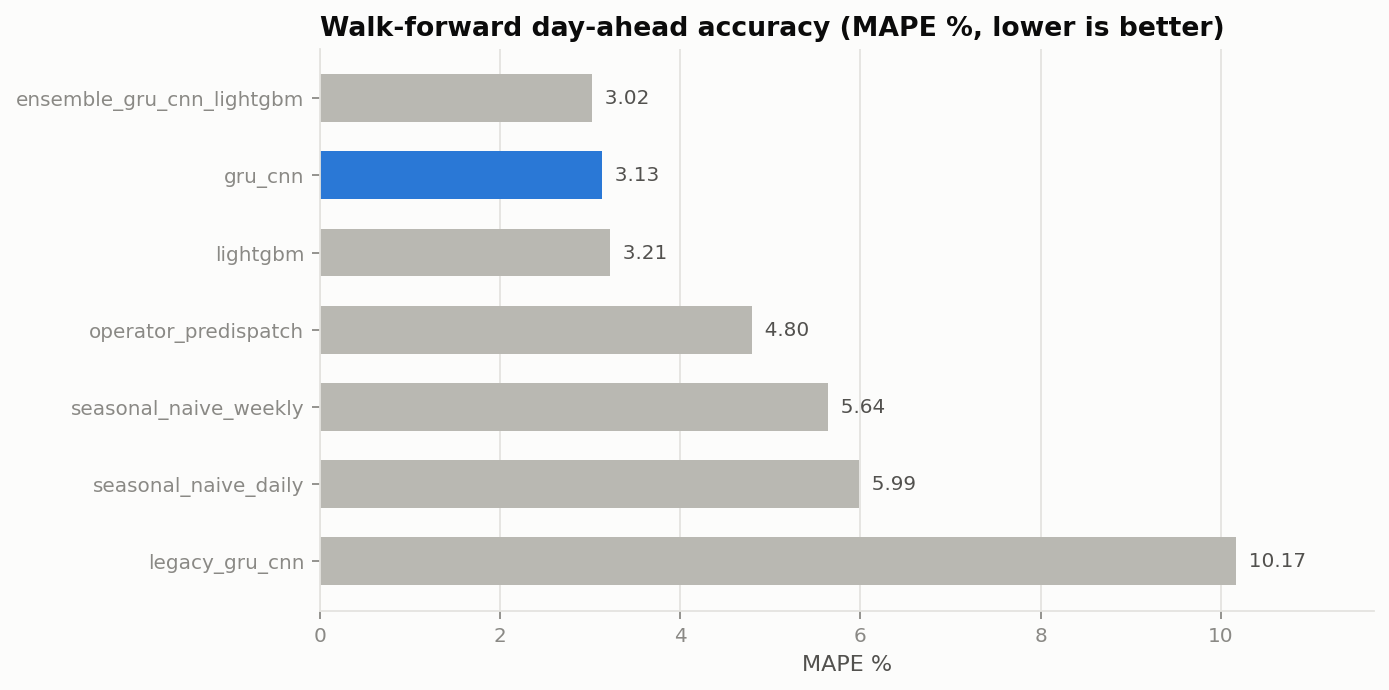

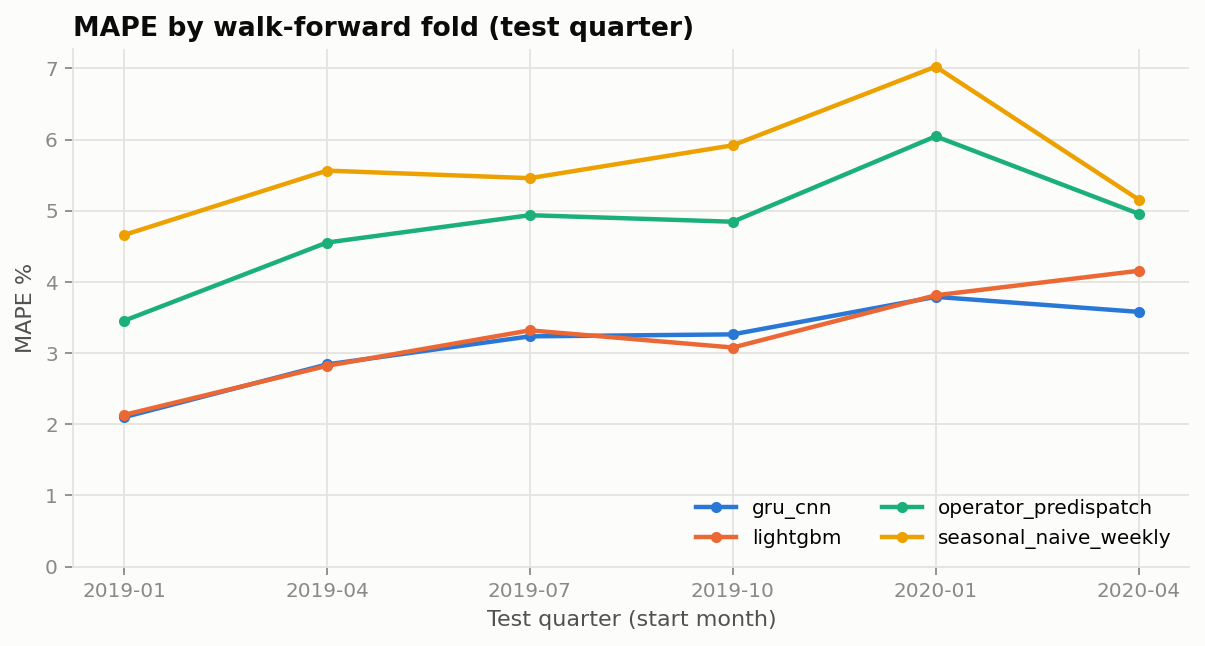

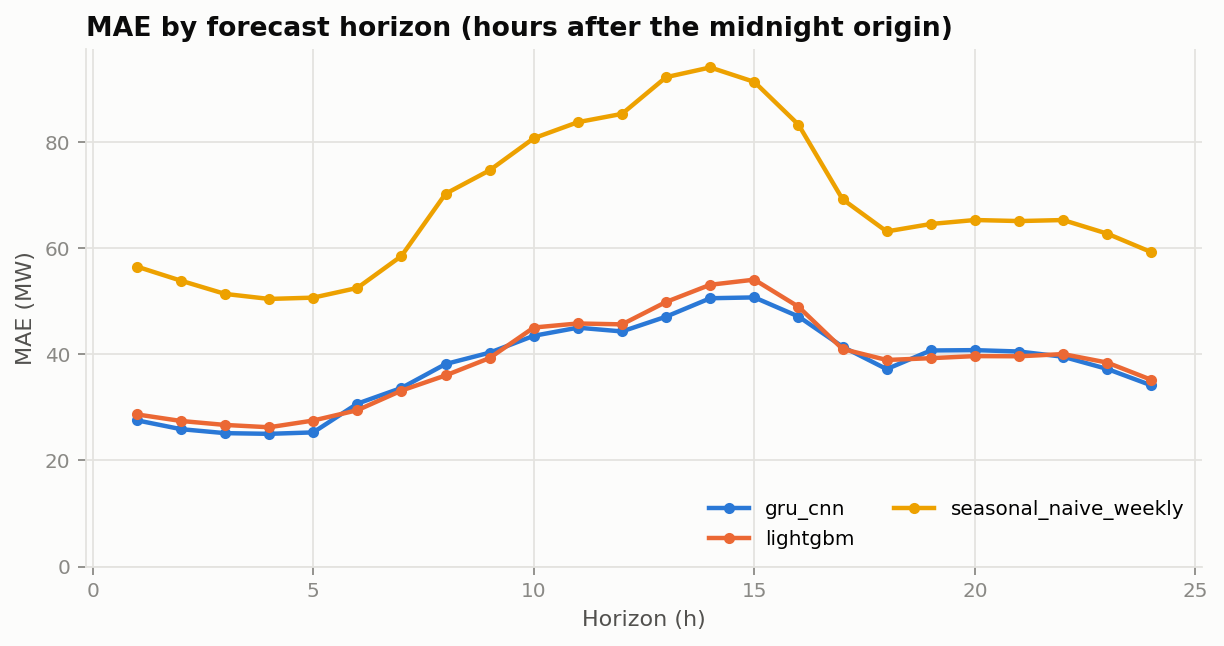

In [10]:
for name in ["benchmark_mape", "mape_by_fold", "mae_by_horizon"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / f"{name}.png"), width=900))

## 6 · Diagnostics of the flagship model

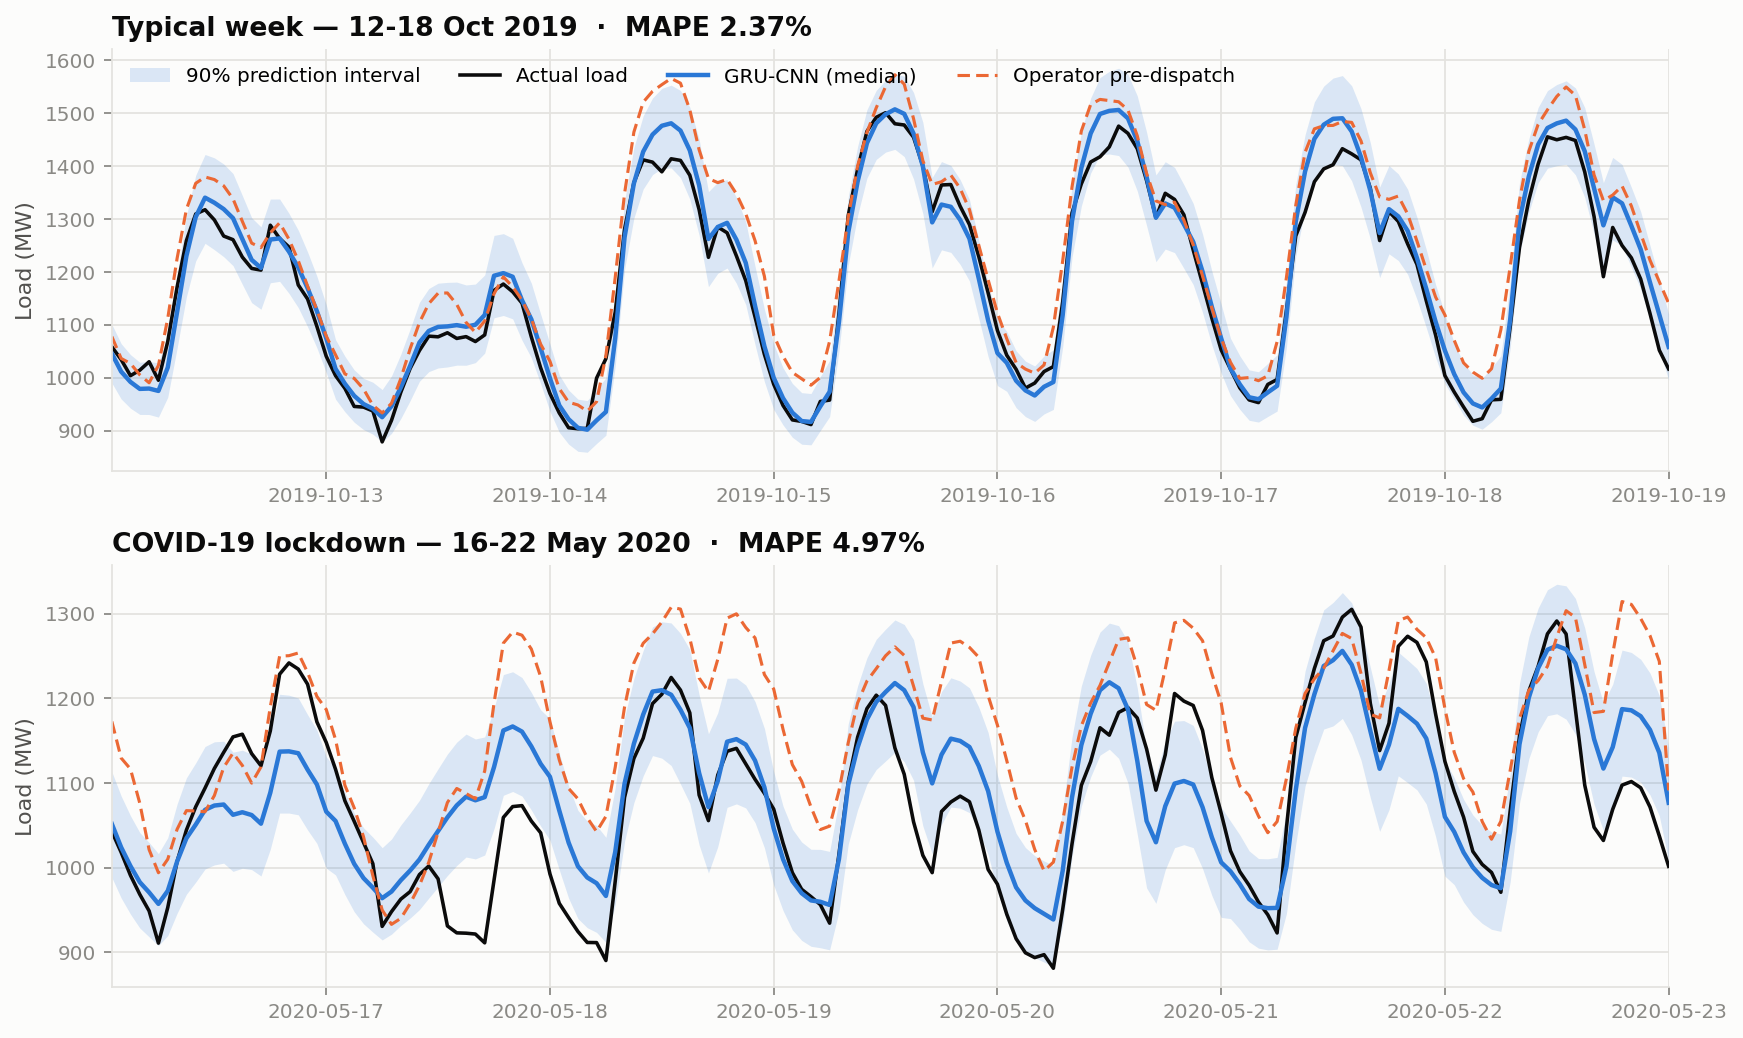

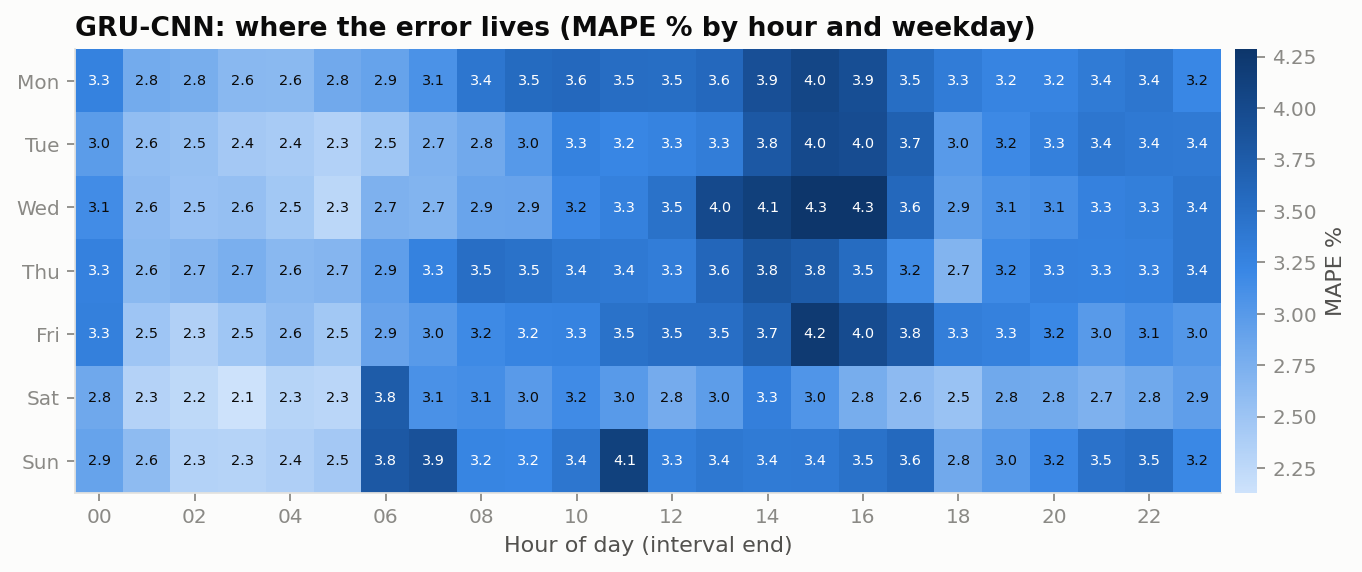

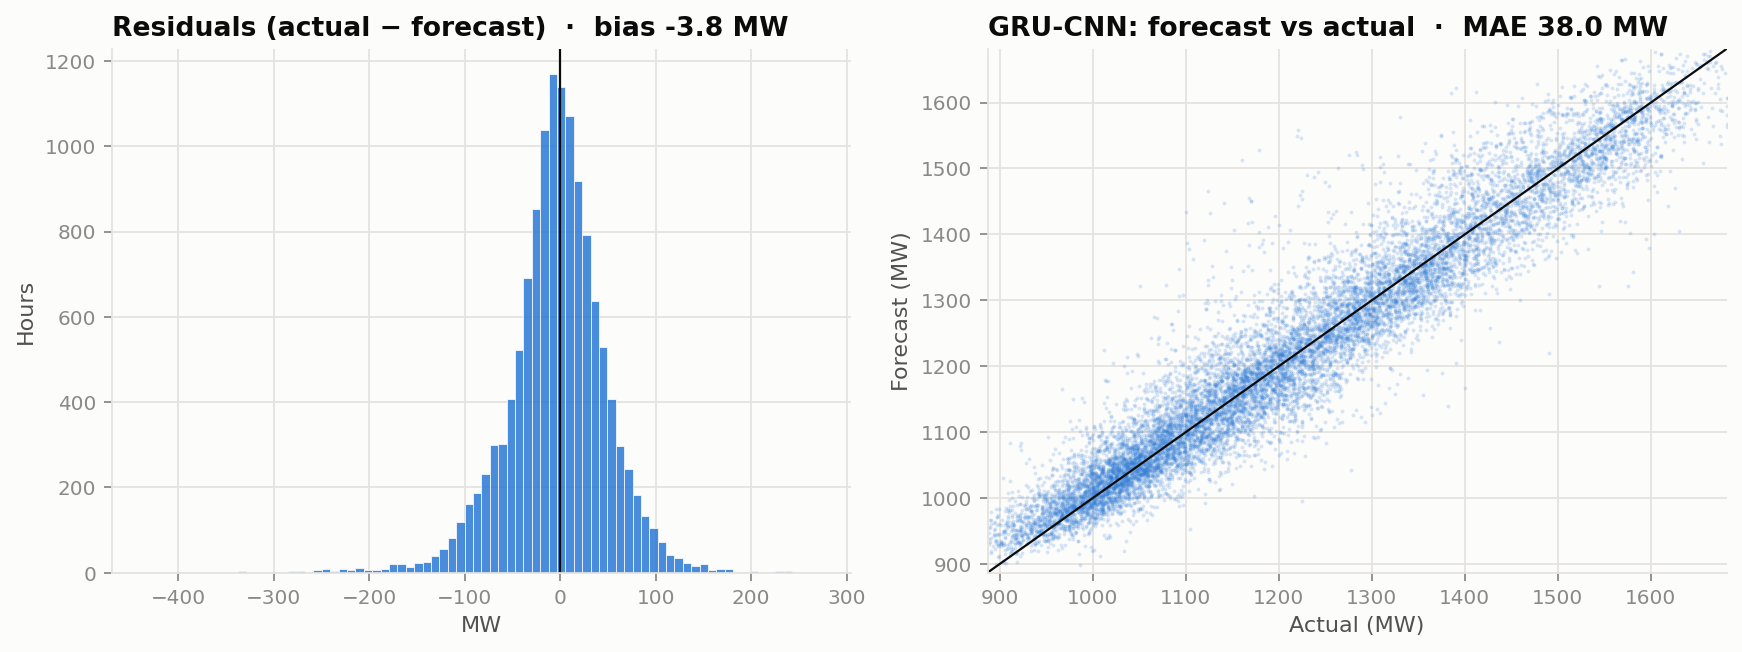

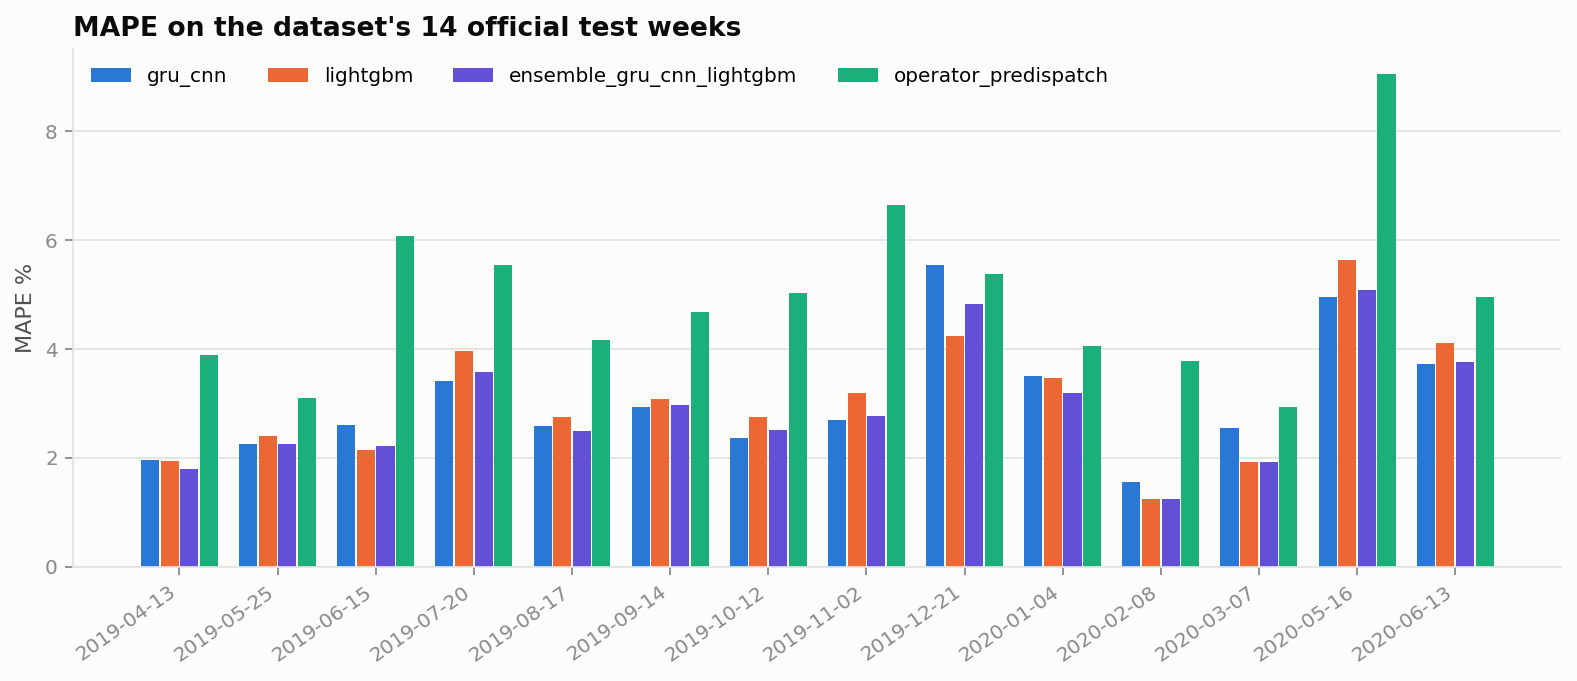

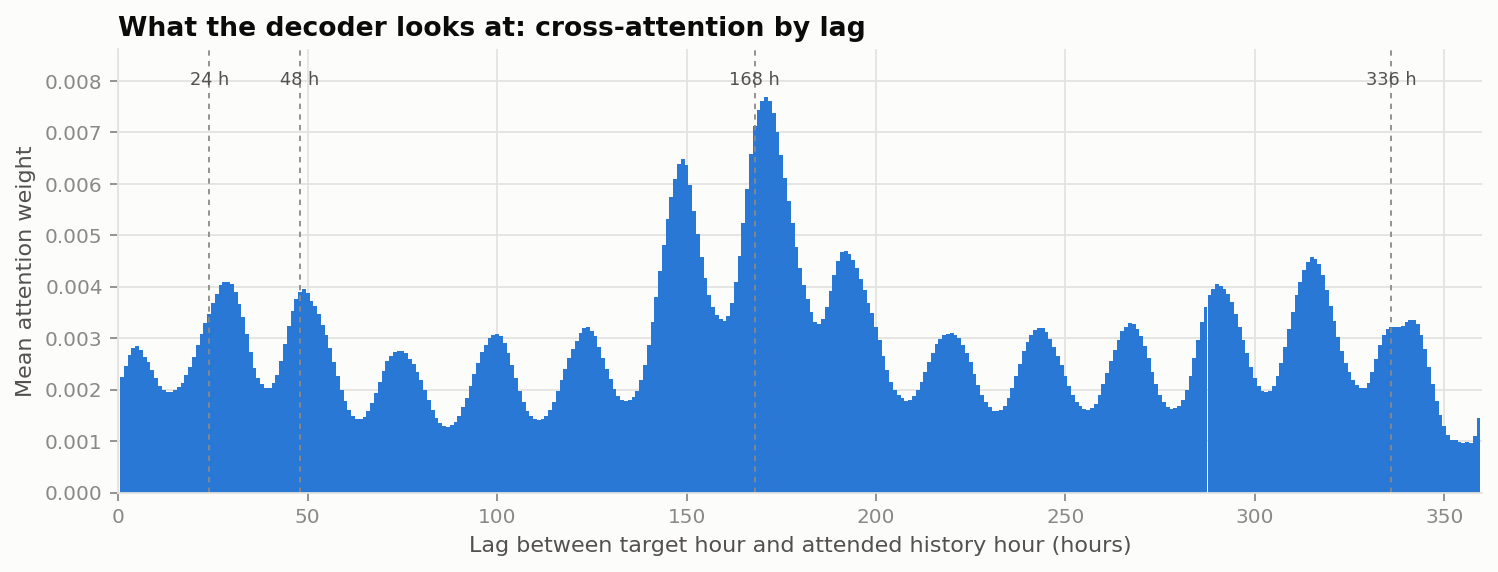

In [11]:
for name in ["forecast_weeks", "error_heatmap", "residuals", "official_weeks", "attention"]:
    path = ROOT / "reports" / "figures" / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path), width=950))

## 7 · Inference from a saved artifact

`train.py` fits the final model on all data (last 8 weeks for early stopping) and writes an
artifact folder; `predict.py` turns it into a forecast.

In [12]:
from stlf.cli.predict import forecast_frame

artifact = ROOT / "artifacts" / "gru_cnn"
if artifact.exists():
    origin, table = forecast_frame(artifact, None, "2020-06-26 00:00")
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.fill_between(
        table["target_time"],
        table["q0.05"],
        table["q0.95"],
        color=plots.SERIES[0],
        alpha=0.16,
        linewidth=0,
        label="90% interval",
    )
    ax.plot(table["target_time"], table["actual"], color=plots.INK, label="actual")
    ax.plot(table["target_time"], table["q0.50"], color=plots.SERIES[0], label="forecast (median)")
    ax.set_title(
        f"Day-ahead forecast issued {origin:%Y-%m-%d %H:%M} (in-sample for the final model)"
    )
    ax.set_ylabel("MW")
    ax.legend(loc="upper left")
    display(table.round(1).head(8))
else:
    print("Run `python train.py --config configs/gru_cnn.yaml` first.")

,target_time,horizon,q0.05,q0.50,q0.95,actual
0,2020-06-26 01:00:00,1,982.7,1059.0,1129.8,1068.3
1,2020-06-26 02:00:00,2,960.3,1032.7,1101.7,1040.0
2,2020-06-26 03:00:00,3,943.7,1014.0,1081.8,1016.4
3,2020-06-26 04:00:00,4,935.2,1004.3,1072.1,1000.7
4,2020-06-26 05:00:00,5,931.3,1000.7,1069.2,997.9
5,2020-06-26 06:00:00,6,934.2,1004.9,1074.6,998.4
6,2020-06-26 07:00:00,7,995.1,1075.1,1148.5,1063.6
7,2020-06-26 08:00:00,8,1083.9,1173.8,1250.6,1145.2


## 8 · Takeaways

* Giving the network the **load history** is by far the largest gain over the 2024 notebook,
  which forecast from weather alone; correcting the protocol (chronological folds, train-only
  scaling, separate validation) is what makes the reported numbers trustworthy.
* See the README for the full results discussion, including where a gradient-boosted tree
  model remains competitive, and the limitations (observed weather used as a perfect forecast,
  a single country, an 18-month test window).